# 02 — Análise exploratória dos dados

Este notebook substitui a resposta artificial do exemplo do professor pelos dados reais da Entrega 2. A análise começa no conjunto completo, passa ao recorte STEM + Junior e termina com os oito grupos definidos pela regra principal de mediana.

**Resposta:** ΔGPA = GPA pós − GPA pré. **Fatores:** A = tipo de uso de IA; B = ansiedade; C = horas tradicionais de estudo. O corte é calculado dentro do recorte STEM + Junior.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

from visualizacoes import (
    configure_plots, plot_cell_counts, plot_factorial_cube,
    plot_protocol_flow, plot_quality_dashboard, save_figure,
)
from scipy import stats
from IPython.display import display

configure_plots()

DATA_NAME = "ai_student_impact_dataset.csv"
ROOT = next(
    (base for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "csv" / DATA_NAME).is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        f"Não encontrei csv/{DATA_NAME} em nenhum diretório ancestral "
        f"do diretório atual: {Path.cwd()}"
    )
CSV_PATH = ROOT / "csv" / DATA_NAME
df = pd.read_csv(CSV_PATH)

required = {
    "Student_ID", "Major_Category", "Year_of_Study", "Pre_Semester_GPA",
    "Post_Semester_GPA", "Primary_Use_Case", "Anxiety_Level_During_Exams",
    "Traditional_Study_Hours",
}
missing_columns = required.difference(df.columns)
if missing_columns:
    raise ValueError(f"Colunas obrigatórias ausentes no CSV: {sorted(missing_columns)}")

df["Delta_GPA"] = df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]
PASSIVE_USE_CASES = {"Copywriting/Drafting", "Direct_Answer_Generation"}
df["A"] = np.where(df["Primary_Use_Case"].isin(PASSIVE_USE_CASES), 1, -1)
stem_junior = df.loc[
    (df["Major_Category"] == "STEM") & (df["Year_of_Study"] == "Junior")
].copy()

ANXIETY_Q2 = stem_junior["Anxiety_Level_During_Exams"].median()
STUDY_Q2 = stem_junior["Traditional_Study_Hours"].median()
stem_junior["B"] = np.where(
    stem_junior["Anxiety_Level_During_Exams"] > ANXIETY_Q2, 1, -1
)
stem_junior["C"] = np.where(
    stem_junior["Traditional_Study_Hours"] > STUDY_Q2, 1, -1
)
factorial = stem_junior.copy()

YATES = ["(1)", "a", "b", "ab", "c", "ac", "bc", "abc"]
CELLS = [
    (a, b, c)
    for c in (-1, 1)
    for b in (-1, 1)
    for a in (-1, 1)
]
cell_number = {cell: number for number, cell in enumerate(CELLS, start=1)}
factorial["celula"] = [
    cell_number[(int(row.A), int(row.B), int(row.C))]
    for row in factorial[["A", "B", "C"]].itertuples(index=False)
]
groups = {
    key: frame["Delta_GPA"].to_numpy()
    for key, frame in factorial.groupby(["A", "B", "C"], sort=False)
}
cell_counts = factorial.groupby(["A", "B", "C"]).size()
if set(groups) != set(CELLS):
    raise ValueError("A classificação não produziu as oito células fatoriais.")
if factorial["Delta_GPA"].isna().any():
    raise ValueError("Há ΔGPA ausente; resolva os dados ausentes antes da análise.")

print(f"Arquivo: {CSV_PATH}")
print(f"Dataset completo: n={len(df):,}")
print(f"Recorte STEM + Junior: n={len(stem_junior):,}")
print(f"Analisados nas oito células: n={len(factorial):,}")
print(f"Cortes: ansiedade Q2={ANXIETY_Q2:g}; estudo Q2={STUDY_Q2:.2f} h")
print(f"Menor célula: n={cell_counts.min():,}")

configure_plots()


Arquivo: /home/wagner/pcc170/csv/ai_student_impact_dataset.csv
Dataset completo: n=50,000
Recorte STEM + Junior: n=3,279
Analisados nas oito células: n=3,279
Cortes: ansiedade Q2=4; estudo Q2=10.91 h
Menor célula: n=181


## Descritivas e distribuição da resposta

A exploração descreve a distribuição e os cortes, sem usar testes de hipótese para selecionar fatores.

,count,mean,std,min,25%,50%,75%,max
Delta_GPA,3279.0,0.240,0.193,-0.853,0.123,0.240,0.365,0.885
Pre_Semester_GPA,3279.0,3.142,0.484,1.294,2.829,3.208,3.517,3.990
Post_Semester_GPA,3279.0,3.383,0.498,1.000,3.056,3.467,3.798,4.000
Anxiety_Level_During_Exams,3279.0,4.422,2.229,1.000,3.000,4.000,6.000,10.000
Traditional_Study_Hours,3279.0,11.038,5.289,1.000,7.330,10.910,14.475,29.750


Ansiedade: mediana=4; proporção ≤ Q2=53.4%
Horas de estudo: mediana=10.91; proporção ≤ Q2=50.0%


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Figura salva: 02_distribuicoes_delta_gpa_fatores.png (PNG) e 02_distribuicoes_delta_gpa_fatores.pdf (PDF)


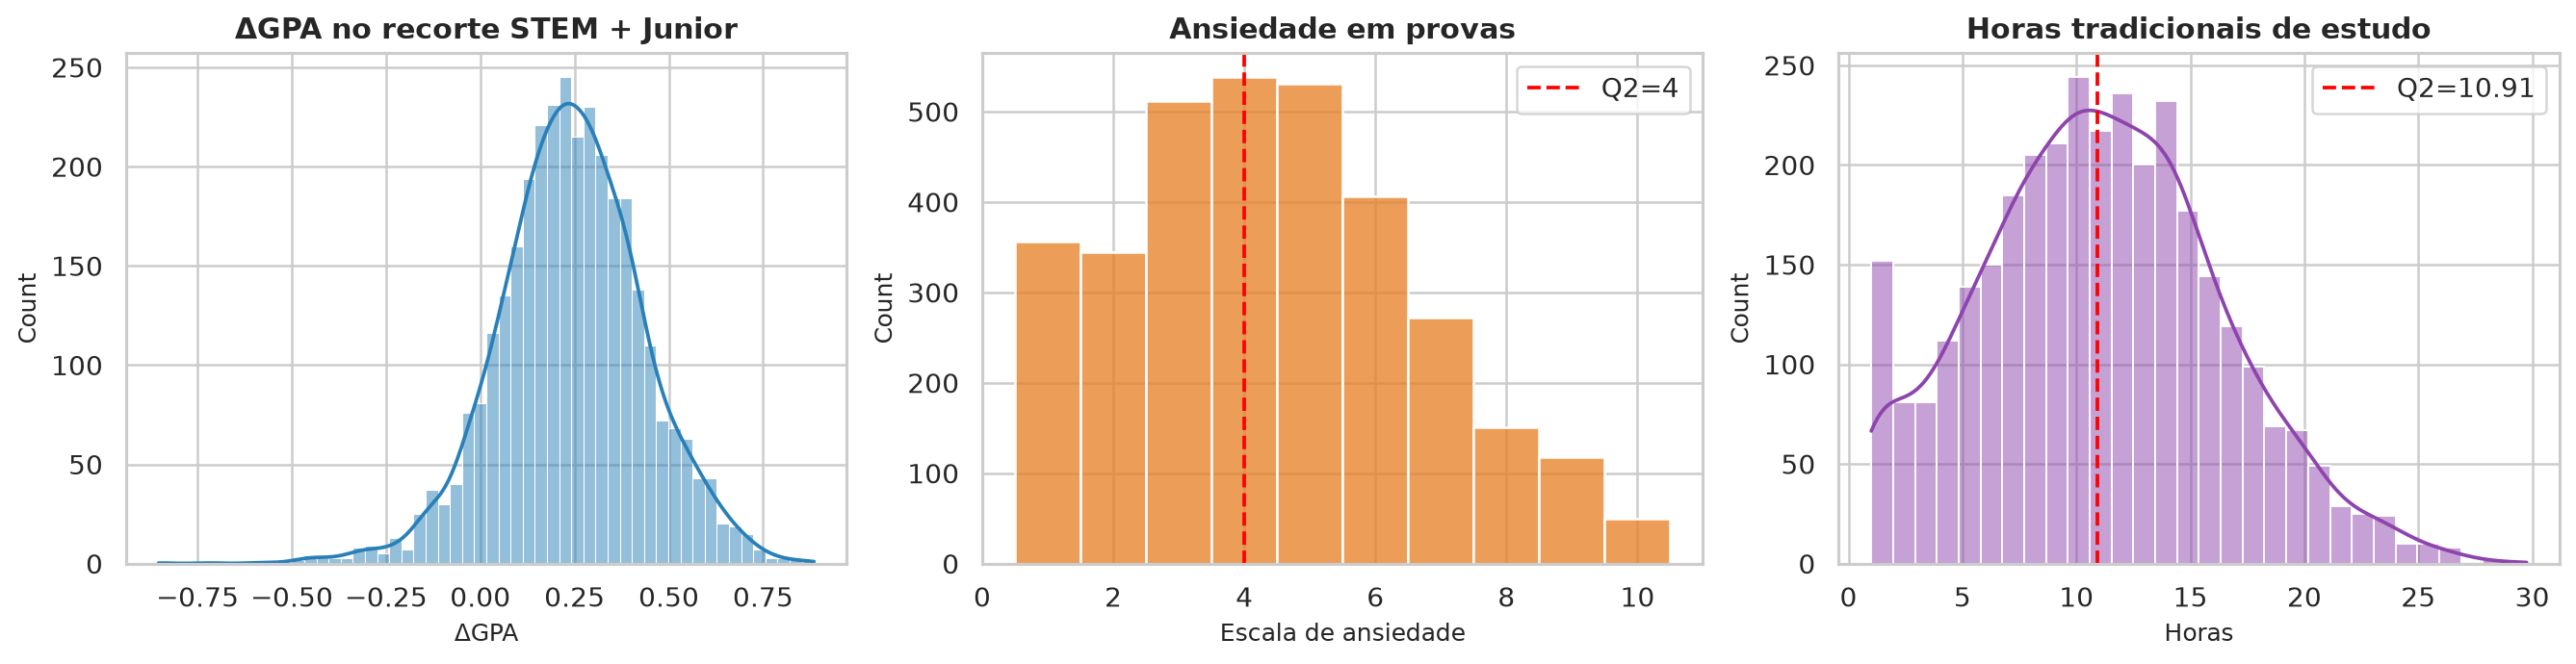

In [2]:

display(
    factorial[[
        "Delta_GPA", "Pre_Semester_GPA", "Post_Semester_GPA",
        "Anxiety_Level_During_Exams", "Traditional_Study_Hours",
    ]].describe().T.round(3)
)
print(
    f"Ansiedade: mediana={ANXIETY_Q2:g}; "
    f"proporção ≤ Q2={(stem_junior['Anxiety_Level_During_Exams'] <= ANXIETY_Q2).mean():.1%}"
)
print(
    f"Horas de estudo: mediana={STUDY_Q2:.2f}; "
    f"proporção ≤ Q2={(stem_junior['Traditional_Study_Hours'] <= STUDY_Q2).mean():.1%}"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(stem_junior["Delta_GPA"], kde=True, ax=axes[0], color="#2980b9")
axes[0].set(title="ΔGPA no recorte STEM + Junior", xlabel="ΔGPA")
sns.histplot(stem_junior["Anxiety_Level_During_Exams"], discrete=True, ax=axes[1], color="#e67e22")
axes[1].axvline(ANXIETY_Q2, color="red", linestyle="--", label=f"Q2={ANXIETY_Q2:g}")
axes[1].set(title="Ansiedade em provas", xlabel="Escala de ansiedade")
axes[1].legend()
sns.histplot(stem_junior["Traditional_Study_Hours"], kde=True, ax=axes[2], color="#8e44ad")
axes[2].axvline(STUDY_Q2, color="red", linestyle="--", label=f"Q2={STUDY_Q2:.2f}")
axes[2].set(title="Horas tradicionais de estudo", xlabel="Horas")
axes[2].legend()
plt.tight_layout()
save_figure(fig, "02_distribuicoes_delta_gpa_fatores")


## Tamanhos das células e resposta por fator

Desbalanceamento não invalida a estimativa por si só, mas afeta precisão e torna importante explicitar os métodos robustos usados depois.

C      C=−1  C=+1
A  B             
−1 −1   667   639
   +1   576   584
+1 −1   210   235
   +1   187   181

Figura salva: 02_boxplot_delta_gpa_celulas.png (PNG) e 02_boxplot_delta_gpa_celulas.pdf (PDF)


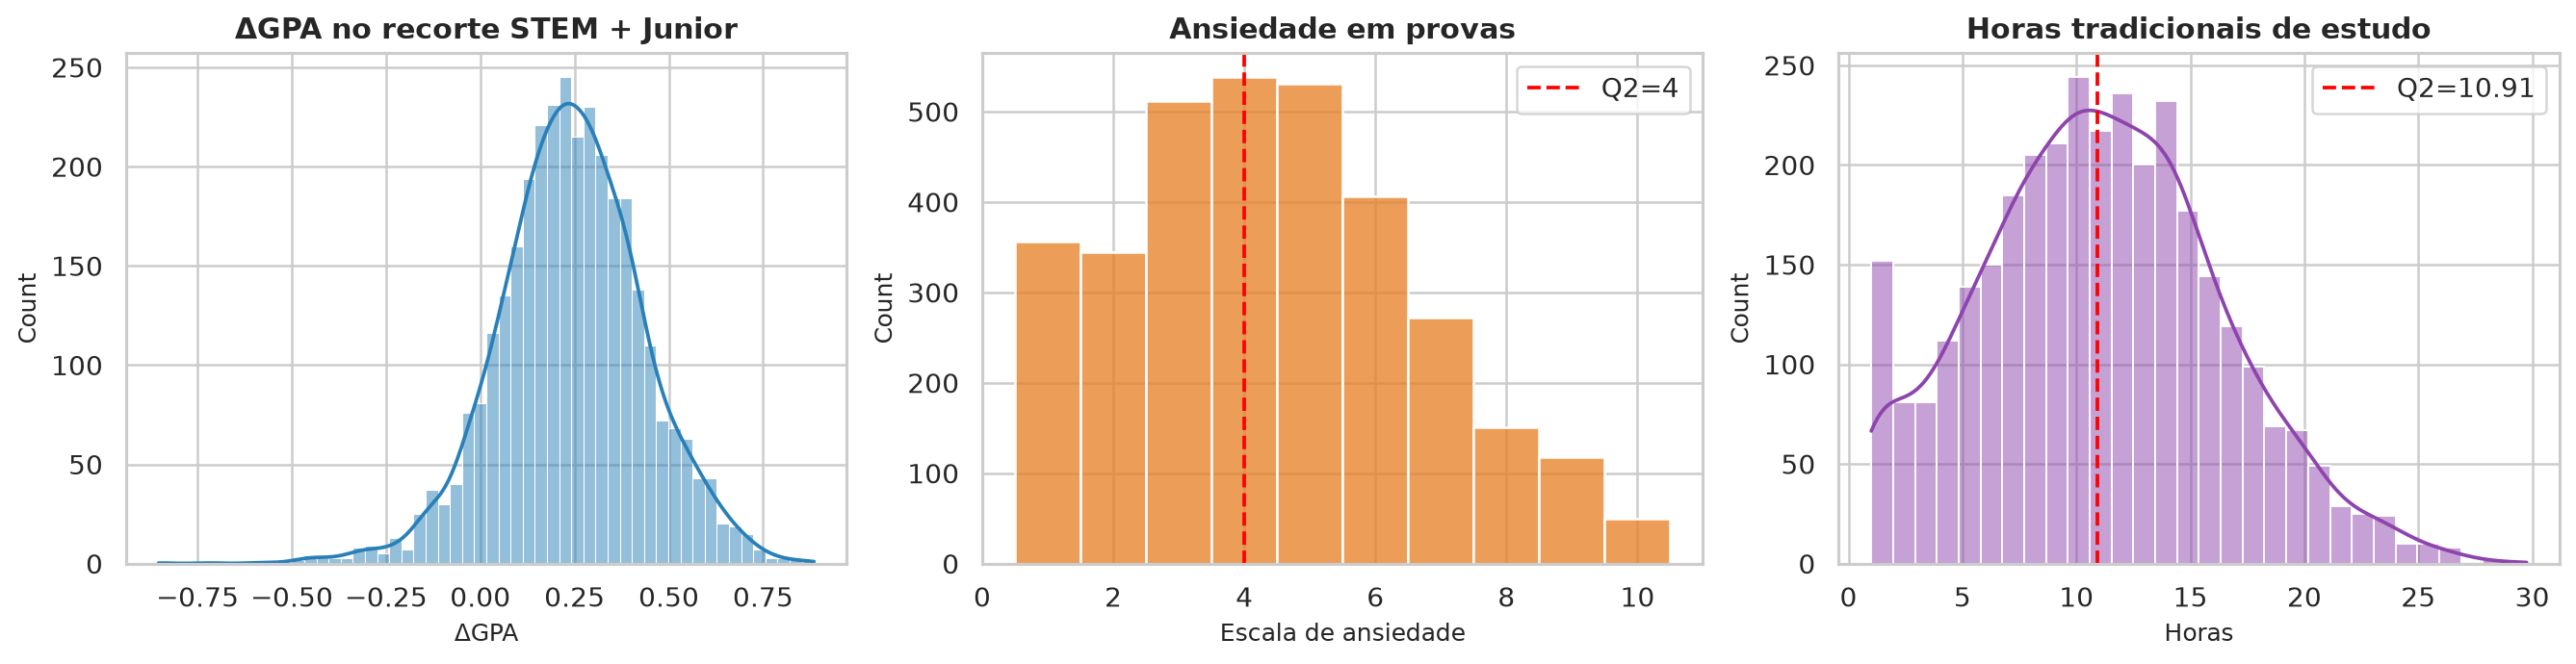

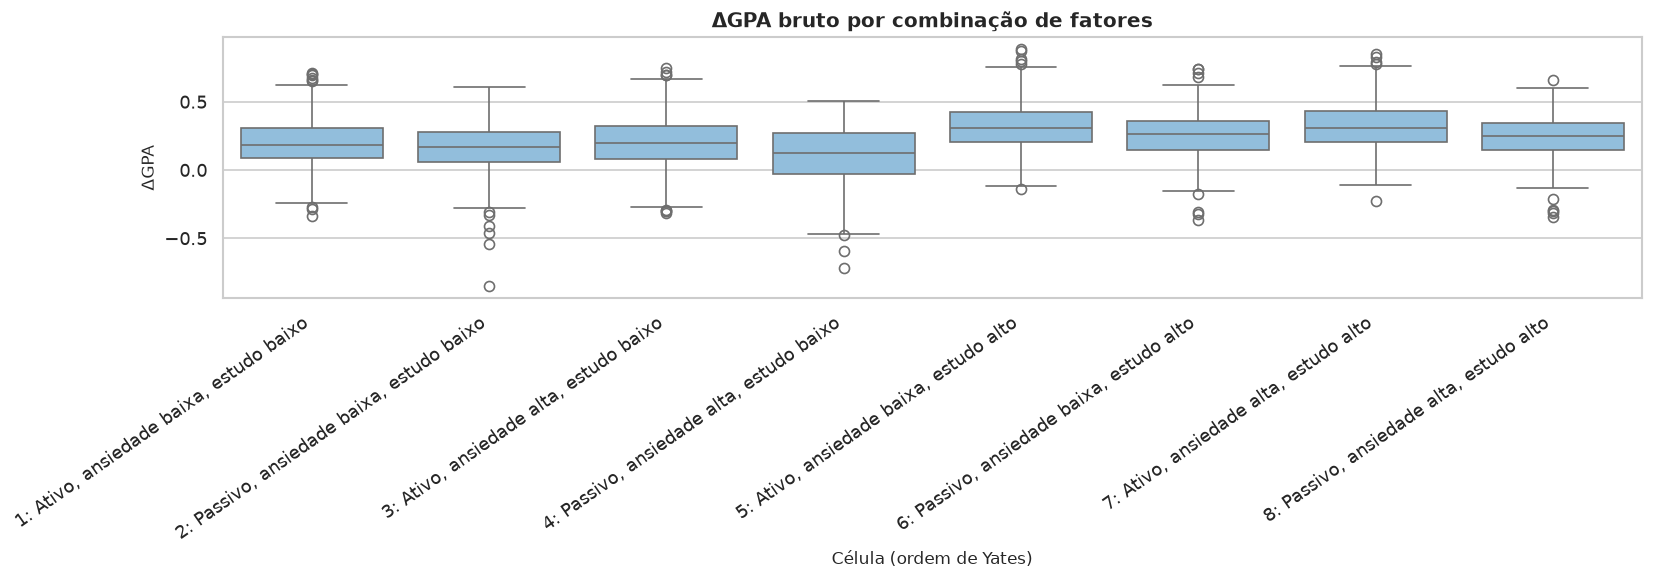

In [3]:

count_table = factorial.pivot_table(
    index=["A", "B"], columns="C", values="Delta_GPA", aggfunc="size", fill_value=0
)
display(count_table.rename(index={-1: "−1", 1: "+1"}, columns={-1: "C=−1", 1: "C=+1"}))

factorial["rotulo_celula"] = factorial.apply(
    lambda row: (
        f"{int(row['celula']) if 'celula' in row else CELLS.index((row['A'], row['B'], row['C'])) + 1}: "
        f"{'Passivo' if row['A'] == 1 else 'Ativo'}, "
        f"ansiedade {'alta' if row['B'] == 1 else 'baixa'}, "
        f"estudo {'alto' if row['C'] == 1 else 'baixo'}"
    ),
    axis=1,
)
order = [
    f"{i + 1}: {'Passivo' if a == 1 else 'Ativo'}, ansiedade {'alta' if b == 1 else 'baixa'}, estudo {'alto' if c == 1 else 'baixo'}"
    for i, (a, b, c) in enumerate(CELLS)
]
plt.figure(figsize=(14, 5))
sns.boxplot(data=factorial, x="rotulo_celula", y="Delta_GPA", order=order, color="#85c1e9")
plt.xticks(rotation=35, ha="right")
plt.xlabel("Célula (ordem de Yates)")
plt.ylabel("ΔGPA")
plt.title("ΔGPA bruto por combinação de fatores")
plt.tight_layout()
save_figure(fig, "02_boxplot_delta_gpa_celulas")


## Distribuição acumulada por fator

As ECDFs mostram a distribuição completa do ΔGPA, sem reduzir a resposta à média.

Figura salva: 02_ecdf_delta_gpa_por_fator.png (PNG) e 02_ecdf_delta_gpa_por_fator.pdf (PDF)


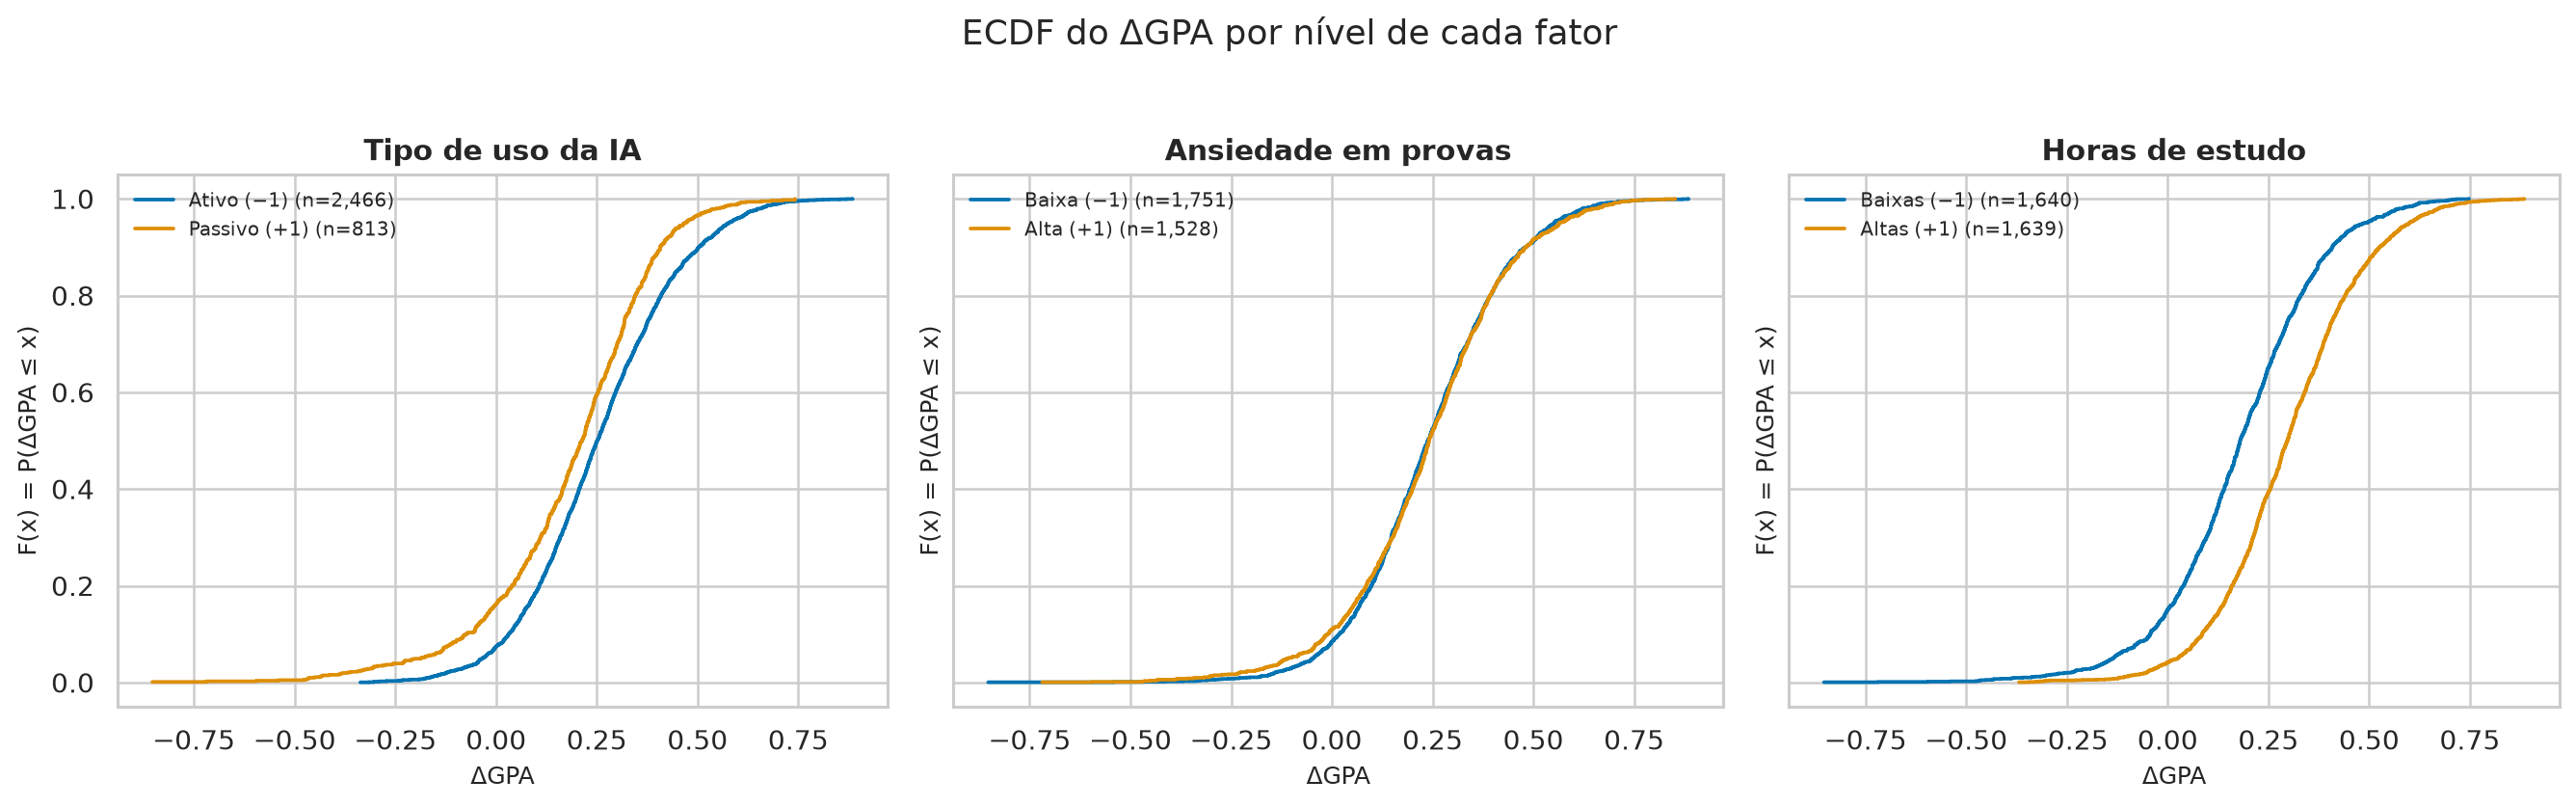

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
factor_columns = [
    ("A", "Tipo de uso da IA", {-1: "Ativo (−1)", 1: "Passivo (+1)"}),
    ("B", "Ansiedade em provas", {-1: "Baixa (−1)", 1: "Alta (+1)"}),
    ("C", "Horas de estudo", {-1: "Baixas (−1)", 1: "Altas (+1)"}),
]
for ax, (factor, title, labels) in zip(axes, factor_columns):
    for level, group in stem_junior.groupby(factor):
        values = np.sort(group["Delta_GPA"].to_numpy())
        cumulative = np.arange(1, len(values) + 1) / len(values)
        ax.step(values, cumulative, where="post", label=f"{labels[level]} (n={len(values):,})")
    ax.set(title=title, xlabel="ΔGPA", ylabel="F(x) = P(ΔGPA ≤ x)")
    ax.legend(fontsize=8, frameon=False)
fig.suptitle("ECDF do ΔGPA por nível de cada fator", y=1.03)
save_figure(fig, "02_ecdf_delta_gpa_por_fator")


## Leitura exploratória

As médias mais altas aparecem nas células com estudo alto e uso ativo; a célula passivo + ansiedade alta + estudo baixo tem média baixa. A amplitude individual dentro de cada célula é muito maior que algumas diferenças entre médias. A inferência formal e o diagnóstico das variâncias são feitos nos notebooks seguintes, não apenas pela inspeção do gráfico.